# Busca de híbridos e seleção incremental

A busca roda em estágios, sempre na validação temporal:

1. **Bases individuais** de várias famílias (estatística, linear, kernel, árvore, neural).
2. **Retenção:** as duas melhores de cada família, o ARIMA e a melhor base geral.
3. **Híbridos residuais:** `ŷ = base + α · corretor(resíduos)`, com corretores Linear, KNN e MLP, janelas de 7 ou 28 resíduos e `α ∈ {0,5; 1}`.
4. **Refinamento** das duas melhores estruturas residuais.
5. **Seleção incremental:** cada família desafia o campeão atual e só o substitui com ganho mediano ≥ 1% e vitórias em ≥ 60% das origens.

Perfil `quickstart`: o critério de variabilidade do protocolo fica desligado, e isso aparece no relatório. O perfil `research_strict` exige esse critério definido.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Dados e experimento

O ARIMA com ordem automática é o modelo mais caro; aqui ele aparece só nos exemplos manuais da seção 3, e a busca automática fica com os demais modelos.

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily")

exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    fold=3,
    fold_strategy="expanding",
    seasonal_period=7,
    profile="quickstart",
    base_models=["naive", "seasonal_naive", "linear", "knn", "mlp"],
    correctors=["linear", "knn", "mlp"],
    residual_windows=[7, 28],
    residual_sources=["historical_oof_1step"],
    alphas=[0.5, 1.0],
    budget="small",
    max_trials=40,
).fit(y)
exp.splits

,layer,train_start,origin,first_target,last_target,n_train,horizon
fold_id,,,,,,,
search-0,search,2024-01-01,2025-09-23,2025-09-24,2025-10-07,632,14
search-1,search,2024-01-01,2025-10-07,2025-10-08,2025-10-21,646,14
search-2,search,2024-01-01,2025-10-21,2025-10-22,2025-11-04,660,14
select-0,select,2024-01-01,2025-11-04,2025-11-05,2025-11-18,674,14
select-1,select,2024-01-01,2025-11-18,2025-11-19,2025-12-02,688,14
select-2,select,2024-01-01,2025-12-02,2025-12-03,2025-12-16,702,14


## 2. Catálogo de modelos

In [3]:
exp.models()

family  multi_step  online_state_update  \
kind      name                                                           
base      arima           statistical        True                 True   
          knn                  kernel        True                 True   
          linear               linear        True                 True   
          mlp                  neural        True                 True   
          naive           statistical        True                 True   
          random_forest          tree        True                 True   
          seasonal_naive  statistical        True                 True   
          svm                  kernel        True                 True   
          tree                   tree        True                 True   
corrector knn               corrector       False                False   
          linear            corrector       False                False   
          mlp               corrector       False                False   

                          in_sample_fitted  deterministic requires_extra  \
kind      name                                                             
base      arima                       True           True          stats   
          knn                        False           True            NaN   
          linear                     False           True            NaN   
          mlp                        False          False            NaN   
          naive                      False           True            NaN   
          random_forest              False          False            NaN   
          seasonal_naive             False           True            NaN   
          svm                        False           True            NaN   
          tree                       False           True            NaN   
corrector knn                        False           True            NaN   
          linear                     False           True            NaN   
          mlp                        False          False            NaN   

                                                                description  
kind      name                                                               
base      arima           ARIMA (statsmodels); ordem automática por KPSS...  
          knn                          k vizinhos mais próximos sobre lags.  
          linear                               Regressão linear sobre lags.  
          mlp                           Perceptron multicamadas sobre lags.  
          naive                            Repete o último valor observado.  
          random_forest                      Floresta aleatória sobre lags.  
          seasonal_naive         Repete a última temporada (season_length).  
          svm                                               SVR sobre lags.  
          tree                                Árvore de decisão sobre lags.  
corrector knn             k vizinhos mais próximos sobre janelas de resí...  
          linear                Regressão linear sobre janelas de resíduos.  
          mlp             Perceptron multicamadas sobre janelas de resíd...

## 3. Um modelo individual e um híbrido montado à mão

Útil para entender as peças antes da busca automática. Os resíduos do corretor são erros de previsão fora da amostra (`historical_oof_1step`), nunca valores ajustados no próprio treino.

In [4]:
arima = exp.create_model("arima")
arima.cv_results

,layer,status,MASE,MAE,RMSE,sMAPE
search-0,search,SUCCEEDED,1.846794,2.865174,3.100497,0.040837
search-1,search,SUCCEEDED,0.554999,0.861073,1.100535,0.012383
search-2,search,SUCCEEDED,1.668095,2.569822,2.698243,0.037090
select-0,select,SUCCEEDED,2.174782,3.346846,3.488244,0.047806
select-1,select,SUCCEEDED,2.195924,3.418777,3.807198,0.048332
select-2,select,SUCCEEDED,0.387069,0.607182,0.739234,0.008558
Mean,NaN,NaN,1.471277,2.278146,2.488992,0.032501
Std,NaN,NaN,0.801855,1.238794,1.276195,0.017626


In [5]:
hybrid = exp.create_hybrid(
    base="arima",
    corrector="mlp",
    window=7,
    alpha=1.0,
    residual_source="historical_oof_1step",
)
hybrid.cv_results

,layer,status,MASE,MAE,RMSE,sMAPE
search-0,search,SUCCEEDED,1.866445,2.895661,3.093652,0.041158
search-1,search,SUCCEEDED,0.555764,0.862260,1.086767,0.012409
search-2,search,SUCCEEDED,1.668606,2.570609,2.692855,0.037114
select-0,select,SUCCEEDED,2.083504,3.206376,3.343848,0.045730
select-1,select,SUCCEEDED,2.161925,3.365846,3.776502,0.047617
select-2,select,SUCCEEDED,0.365805,0.573826,0.722414,0.008059
Mean,NaN,NaN,1.450342,2.245763,2.452673,0.032015
Std,NaN,NaN,0.787974,1.217761,1.254970,0.017317


## 4. Busca automática

In [6]:
result = exp.compare_models(include=["standalone", "residual"], sort="MASE")
result.leaderboard

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
7dd1082a4ee4fe9df20683376c5688b4a23322240929c4c44a8140e266a10ae2,mlp,mlp(lags=7),neural,standalone,mlp,NaN,NaN,NaN,NaN,1.0,...,1.329098,1.590181,0.019224,1.0,3,0,0,1.433780,0.020755,False
9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6,mlp-linear,"mlp(lags=7) + linear [w=7, alpha=0.5, historic...",residual,residual_additive,mlp,linear,historical_oof_1step,7.0,0.5,2.0,...,1.335050,1.622713,0.019335,1.0,3,0,0,4.548033,0.050749,True
459af2c77fe43d1936669c337e695b972b6de79264cfa329ed349dfc20dc5172,mlp-linear,"mlp(lags=7) + linear [w=28, alpha=0.5, histori...",residual,residual_additive,mlp,linear,historical_oof_1step,28.0,0.5,3.0,...,1.536977,1.800618,0.022398,1.0,3,0,0,5.379944,0.055606,False
70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37,knn,knn(lags=7),kernel,standalone,knn,NaN,NaN,NaN,NaN,4.0,...,1.563061,1.966950,0.022621,1.0,3,0,0,0.123958,0.093219,False
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,seasonal_naive,seasonal_naive(season_length=7),statistical,standalone,seasonal_naive,NaN,NaN,NaN,NaN,5.0,...,1.614291,1.909265,0.023346,1.0,3,0,0,0.000259,0.000397,False
e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,6.0,...,1.649719,1.852607,0.023763,1.0,3,0,0,0.128248,0.029531,False
773d3b8c8d625571d4d4b4f4aa234d9f88b9b7fc0ceb3101c126e49e100378fc,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,0.5,7.0,...,1.673298,1.998234,0.024205,1.0,3,0,0,0.523895,0.022612,False
c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1fd3722f7c6ed592f9b,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,8.0,...,1.698826,1.914754,0.024472,1.0,3,0,0,1.167359,0.035377,False
972a9d57c62d5265bf431a410bf8ccd45ae226f2e6bb124bc9d763258cbdbae4,mlp-linear,"mlp(lags=7) + linear [w=7, alpha=1.0, historic...",residual,residual_additive,mlp,linear,historical_oof_1step,7.0,1.0,9.0,...,1.725096,2.009527,0.024833,1.0,3,0,0,4.239787,0.033154,False


## 5. Por que o campeão venceu

`decisions` lista cada desafiante, se foi aceito, o ganho mediano, a taxa de vitórias e os motivos. Rejeições também ficam registradas. `audit` conta todas as tentativas, inclusive as podadas e as que falharam.

In [7]:
result.decisions

,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate,variability_status,variability_value,p_value,challenger_coverage,challenger_label,champion_before_id,challenger_id
0,statistical,mlp,seasonal_naive,True,"(accepted,)",0.034103,0.666667,disabled,None,None,1.0,seasonal_naive(season_length=7),7dd1082a4ee4fe9df20683376c5688b4a23322240929c4...,d90528888825a4459816afbcf249ff909747924f0a2bba...
1,linear,seasonal_naive,linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.063063,0.333333,disabled,None,None,1.0,linear(lags=7),d90528888825a4459816afbcf249ff909747924f0a2bba...,e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...
2,kernel,seasonal_naive,knn,False,"(median_gain_below_threshold, win_rate_below_t...",-0.194760,0.333333,disabled,None,None,1.0,knn(lags=7),d90528888825a4459816afbcf249ff909747924f0a2bba...,70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d...
3,neural,seasonal_naive,mlp,False,"(median_gain_below_threshold, win_rate_below_t...",-0.035307,0.333333,disabled,None,None,1.0,mlp(lags=7),d90528888825a4459816afbcf249ff909747924f0a2bba...,7dd1082a4ee4fe9df20683376c5688b4a23322240929c4...
4,residual,seasonal_naive,mlp-linear,True,"(accepted,)",0.111745,0.666667,disabled,None,None,1.0,"mlp(lags=7) + linear [w=7, alpha=0.5, historic...",d90528888825a4459816afbcf249ff909747924f0a2bba...,9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0...


In [8]:
result.audit

SelectionAudit(protocol_hash='757c5789a92d72399a090b37236edfb97d9c7a3beba72e916cf7abf69b9abc25', search_protocol_hash='064ca1d1fe5cf095992def236a44181abd9e3734fb51b681af4a2e6d94cdf0e2', total_trials=18, tried_by_family={'statistical': 2, 'linear': 1, 'kernel': 1, 'neural': 1, 'residual': 13}, pruned_trials=49, failed_trials=0, finalist_ids=('7dd1082a4ee4fe9df20683376c5688b4a23322240929c4c44a8140e266a10ae2', '9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6', '70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37', 'd90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238', 'e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4'), winner_id='9fd962cca51322c0e3697027ac96d1fa8d35c2672647b0030737ef663dde6df6', comparison_origin_ids=('select-0', 'select-1', 'select-2'), decision_reasons=('statistical: accepted', 'linear: median_gain_below_threshold+win_rate_below_threshold', 'kernel: median_gain_below_threshold+win_rate_below_threshold', 'neural

## 6. Diagnósticos da validação

Todos os gráficos usam previsões fora da amostra nas origens de validação, nunca o teste selado.

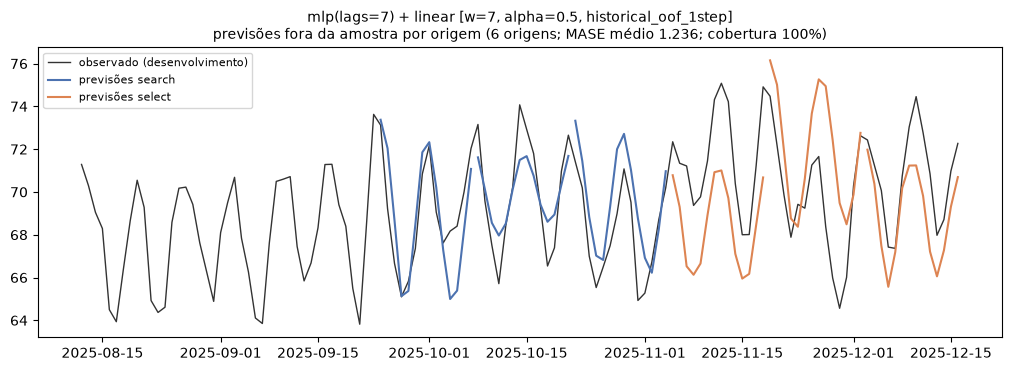

In [9]:
exp.plot_model(result.best, plot="cv_forecasts")

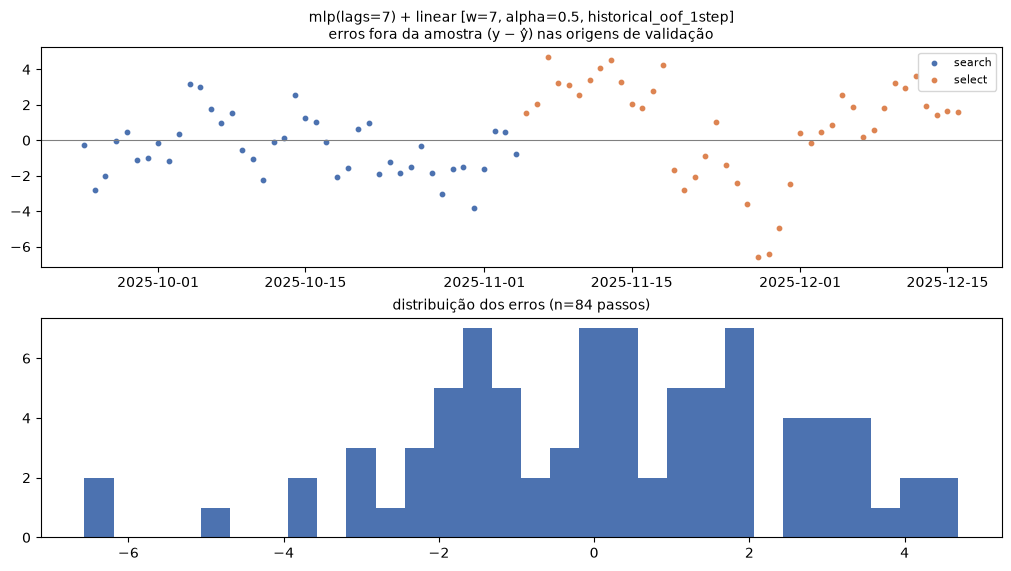

In [10]:
exp.plot_model(result.best, plot="residuals")

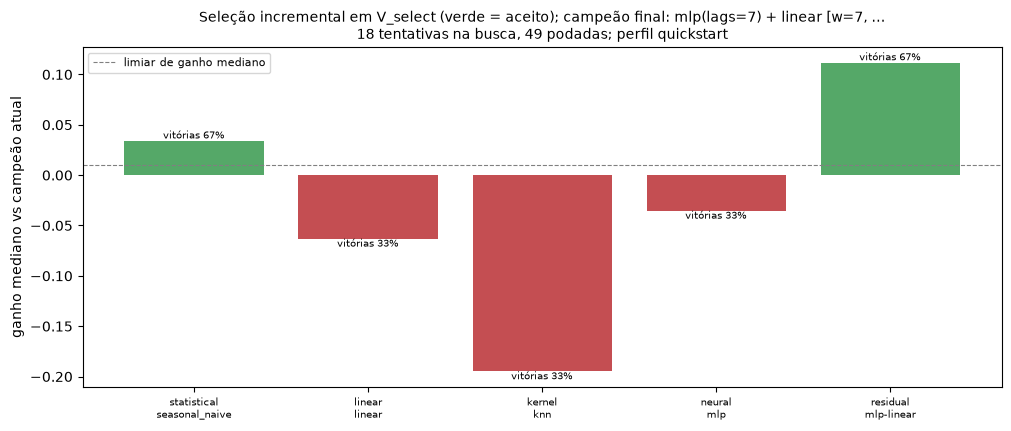

In [11]:
exp.plot_model(result.best, plot="selection_trace")

## 7. Eventos do experimento

In [12]:
for event in exp.events:
    duration = f"{event.duration_ms:9.1f} ms" if event.duration_ms else " " * 12
    print(f"{event.kind:32s} {duration}  {event.message}")

experiment.fitted                     12.7 ms  1 série(s), 716 pontos de desenvolvimento, teste selado de 14 por série, 6 origens
model.created                      50311.8 ms  arima
hybrid.created                     41708.9 ms  arima + mlp [w=7, alpha=1.0, historical_oof_1step]
search.finished                    33263.0 ms  18 tentativas (budget_limited)
selection.finished                  5250.9 ms  campeão: mlp(lags=7) + linear [w=7, alpha=0.5, historical_oof_1step]
